In [1]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_diabetes
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor

In [3]:
data = load_diabetes()
X = pd.DataFrame(data.data , columns=data.feature_names)
y = data.target

In [4]:
print(X.shape)

(442, 10)


In [6]:
print(X.head())

        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  
0 -0.002592  0.019907 -0.017646  
1 -0.039493 -0.068332 -0.092204  
2 -0.002592  0.002861 -0.025930  
3  0.034309  0.022688 -0.009362  
4 -0.002592 -0.031988 -0.046641  


In [7]:
print(y[:5])

[151.  75. 141. 206. 135.]


In [8]:
models = {
    "Linear Regression": LinearRegression(),
    "Deicion Tree" : DecisionTreeRegressor(
        random_state=42
    ),
    "KNN" : make_pipeline(
        StandardScaler(),
        KNeighborsRegressor(n_neighbors=5)
    )
}

In [17]:
results = []
for name,model in models.items():
    scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring='r2'
    )

results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean R2": scores.mean(),
        "Std Deviation": scores.std()
    })

results_df = pd.DataFrame(results)

print(results_df.round(4))

  Model  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean R2  Std Deviation
0   KNN  0.3291  0.3792  0.4245  0.3067  0.4053    0.369         0.0447


In [18]:
best_model = results_df.loc[
    results_df["Mean R2"].idxmax()
]


In [19]:
print("Best Model:", best_model["Model"])
print("Mean R2 Score:", round(best_model["Mean R2"], 4))
print("Standard Deviation:", round(best_model["Std Deviation"], 4))

Best Model: KNN
Mean R2 Score: 0.369
Standard Deviation: 0.0447


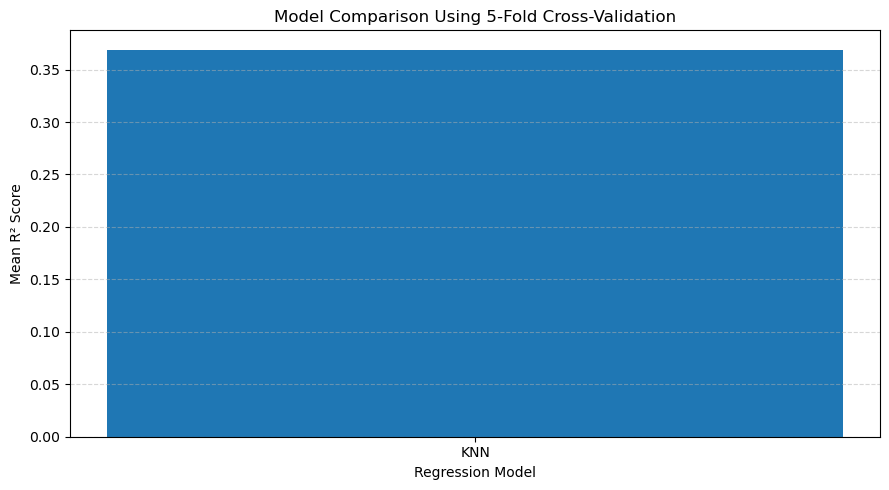

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    results_df["Model"],
    results_df["Mean R2"]
)

plt.title("Model Comparison Using 5-Fold Cross-Validation")
plt.xlabel("Regression Model")
plt.ylabel("Mean R² Score")
plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()